# Consumer Purchase Prediction in E-Commerce
Replicates Esmeli & Gokce (2025) on the **UCI Online Shoppers Purchasing Intention** dataset.

- **Task**: Binary classification — will a visitor purchase?
- **Models**: LR, DT, KNN, RF, GB, MLP, CNN, LSTM (8 models as in the paper)
- **Evaluation**: F1, Recall, Precision, ROC-AUC via 5-fold stratified CV + SMOTE
- **Dataset**: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

In [1]:
import subprocess
subprocess.run(['pip', 'install', 'imbalanced-learn', '-q'], capture_output=True)

import os, copy, time, random, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, recall_score, precision_score,
                              roc_auc_score, roc_curve,
                              confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

In [2]:
#Fix the random seed
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
devices = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {devices}')

#Number of CV folds (paper uses 10; set lower for speed)
n_splits = 5

Device: cuda


## Stage 1 — Data Collection

In [3]:
data_path = 'data_ecommerce'
os.makedirs(data_path, exist_ok=True)
data_file = os.path.join(data_path, 'online_shoppers_intention.csv')

#Download once and cache to CSV
if not os.path.exists(data_file):
    import urllib.request
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv'
    urllib.request.urlretrieve(url, data_file)
    print('Dataset downloaded.')

df = pd.read_csv(data_file)
print(f'Shape: {df.shape}')
df.head()

Dataset downloaded.
Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
#Dataset summary
print('Dtypes:')
print(df.dtypes)
print(f'\nMissing values: {df.isnull().sum().sum()}')
print('\nTarget distribution:')
vc = df['Revenue'].value_counts()
print(vc)
print(f'Purchase rate: {df["Revenue"].mean():.2%}')

Dtypes:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

Missing values: 0

Target distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64
Purchase rate: 15.47%


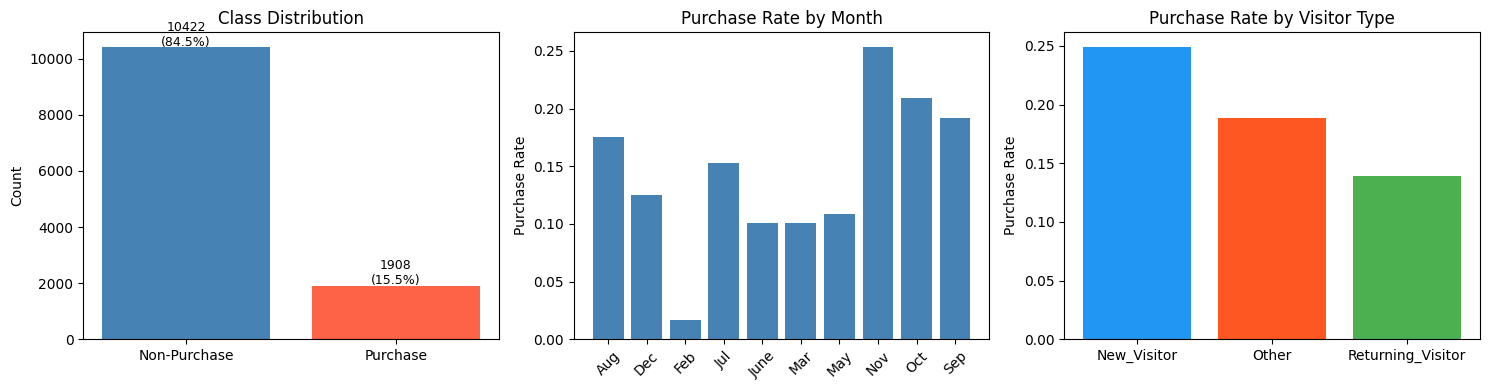

In [5]:
#Plot class distribution, purchase rate by month and visitor type
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

counts = [vc[False], vc[True]]
axes[0].bar(['Non-Purchase', 'Purchase'], counts, color=['steelblue', 'tomato'])
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts):
    axes[0].text(i, v + 50, f'{v}\n({v/len(df):.1%})', ha='center', fontsize=9)

month_rate = df.groupby('Month')['Revenue'].mean()
axes[1].bar(month_rate.index, month_rate.values, color='steelblue')
axes[1].set_title('Purchase Rate by Month')
axes[1].set_ylabel('Purchase Rate')
axes[1].tick_params(axis='x', rotation=45)

vtype_rate = df.groupby('VisitorType')['Revenue'].mean()
axes[2].bar(vtype_rate.index, vtype_rate.values,
            color=['#2196F3', '#FF5722', '#4CAF50'])
axes[2].set_title('Purchase Rate by Visitor Type')
axes[2].set_ylabel('Purchase Rate')

plt.tight_layout()
plt.show()

## Stage 2 — Feature Engineering

In [6]:
#Total pages viewed across all categories (paper: 'pagesviewed')
df['pages_viewed'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

#Total session duration
df['total_duration'] = (df['Administrative_Duration'] +
                        df['Informational_Duration'] +
                        df['ProductRelated_Duration'])

#Category transitions: number of distinct page types visited (paper: '#catchanges')
df['cat_transitions'] = ((df['Administrative'] > 0).astype(int) +
                         (df['Informational'] > 0).astype(int) +
                         (df['ProductRelated'] > 0).astype(int))

#Session engagement quality = 1 - BounceRate
df['engagement_quality'] = 1 - df['BounceRates']

#Price sensitivity proxy: PageValues indicates how valuable the pages were
df['price_sensitivity'] = df['PageValues']

#Special day flag — near holiday, proxy for price change events (paper: 'pricechange')
df['is_special_day'] = (df['SpecialDay'] > 0).astype(int)

print('Engineered features added:')
df[['pages_viewed', 'total_duration', 'cat_transitions',
    'engagement_quality', 'price_sensitivity', 'is_special_day']].describe()

Engineered features added:


,pages_viewed,total_duration,cat_transitions,engagement_quality,price_sensitivity,is_special_day
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,34.550203,1310.037228,1.742498,0.977809,5.889258,0.101460
std,46.514053,2037.801702,0.737369,0.048488,18.568437,0.301949
min,0.000000,0.000000,0.000000,0.800000,0.000000,0.000000
25%,8.000000,222.000000,1.000000,0.983187,0.000000,0.000000
50%,20.000000,680.000000,2.000000,0.996888,0.000000,0.000000
75%,42.000000,1626.908333,2.000000,1.000000,0.000000,0.000000
max,746.000000,69921.647230,3.000000,1.000000,361.763742,1.000000


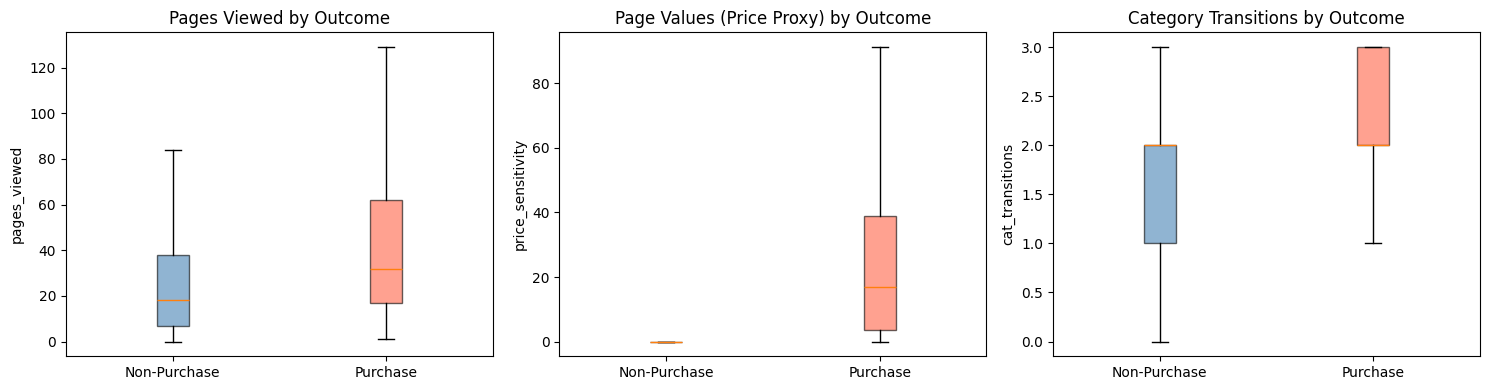

In [7]:
#Box plots of key engineered features by purchase outcome
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features_to_plot = ['pages_viewed', 'price_sensitivity', 'cat_transitions']
titles = ['Pages Viewed by Outcome', 'Page Values (Price Proxy) by Outcome',
          'Category Transitions by Outcome']

for ax, feat, title in zip(axes, features_to_plot, titles):
    for label, color in [(False, 'steelblue'), (True, 'tomato')]:
        data = df[df['Revenue'] == label][feat]
        bp = ax.boxplot(data, positions=[0 if not label else 1],
                        patch_artist=True,
                        boxprops=dict(facecolor=color, alpha=0.6),
                        showfliers=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Non-Purchase', 'Purchase'])
    ax.set_title(title)
    ax.set_ylabel(feat)

plt.tight_layout()
plt.show()

## Stage 3 — Preprocessing & Model Development

In [8]:
df_enc = df.copy()

#Encode Month
month_map = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6,
             'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
df_enc['Month'] = df_enc['Month'].map(month_map)

#Encode VisitorType
visitor_map = {'Returning_Visitor': 0, 'New_Visitor': 1, 'Other': 2}
df_enc['VisitorType'] = df_enc['VisitorType'].map(visitor_map)

#Convert booleans
df_enc['Weekend'] = df_enc['Weekend'].astype(int)
df_enc['Revenue'] = df_enc['Revenue'].astype(int)

feature_cols = [c for c in df_enc.columns if c != 'Revenue']
X = df_enc[feature_cols].values.astype(np.float32)
y = df_enc['Revenue'].values.astype(np.int64)

#Normalize the data
scaler = StandardScaler()
X = scaler.fit_transform(X)

print(f'X shape: {X.shape}')
print(f'Feature count: {X.shape[1]}')
print(f'Class balance: {np.bincount(y)} (Non-Purchase / Purchase)')

X shape: (12330, 23)
Feature count: 23
Class balance: [10422  1908] (Non-Purchase / Purchase)


In [9]:
class ShopperDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

#Show one sample
sx, sy = ShopperDataset(X, y)[0]
print(f'Sample X shape: {sx.shape}, label: {sy.item()}')

Sample X shape: torch.Size([23]), label: 0


In [10]:
#Sklearn model definitions
sklearn_models = {
    'LR':  LogisticRegression(max_iter=1000, random_state=seed),
    'DT':  DecisionTreeClassifier(max_depth=10, random_state=seed),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'RF':  RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1),
    'GB':  GradientBoostingClassifier(n_estimators=100, random_state=seed),
}

In [11]:
class MLP_Classifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, drop=0.3):
        super(MLP_Classifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(hidden_dim // 2, num_classes)
        )

    def forward(self, x):
        return self.net(x)

In [12]:
class CNN1D_Classifier(nn.Module):
    def __init__(self, input_dim, filters=64, num_classes=2, drop=0.3):
        super(CNN1D_Classifier, self).__init__()
        #Treat feature vector as 1D signal: (batch, 1, input_dim)
        self.conv1 = nn.Conv1d(1, filters, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(filters, filters * 2, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)
        #Compute flattened size dynamically
        dummy = torch.zeros(1, 1, input_dim)
        with torch.no_grad():
            dummy = self.pool(self.relu(self.conv2(self.relu(self.conv1(dummy)))))
        fc_input = dummy.flatten(start_dim=1).shape[1]
        self.fc = nn.Sequential(
            nn.Linear(fc_input, 128),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x: (batch, input_dim) -> (batch, 1, input_dim)
        x = x.unsqueeze(1)
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = self.drop(x)
        x = x.flatten(start_dim=1)
        x = self.fc(x)
        return x

In [13]:
class LSTM_Classifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, num_classes=2, drop=0.3):
        super(LSTM_Classifier, self).__init__()
        #Treat each feature as a time step: (batch, input_dim, 1)
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_dim,
                            num_layers=num_layers, batch_first=True,
                            dropout=drop if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # x: (batch, input_dim) -> (batch, input_dim, 1)
        x = x.unsqueeze(2)
        _, (h_n, _) = self.lstm(x)
        x = self.drop(h_n[-1])
        x = self.fc(x)
        return x

In [14]:
def sklearn_kfold(model, X, y, n_splits=5):
    """Stratified K-fold CV with SMOTE applied only to training folds."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    smote = SMOTE(random_state=seed)
    all_proba, all_preds, all_true = [], [], []

    for train_idx, test_idx in skf.split(X, y):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]
        X_tr_sm, y_tr_sm = smote.fit_resample(X_tr, y_tr)
        m = clone(model)
        m.fit(X_tr_sm, y_tr_sm)
        all_preds.extend(m.predict(X_te))
        all_proba.extend(m.predict_proba(X_te)[:, 1])
        all_true.extend(y_te)

    y_true  = np.array(all_true)
    y_pred  = np.array(all_preds)
    y_proba = np.array(all_proba)
    return {
        'f1':        f1_score(y_true, y_pred),
        'recall':    recall_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'roc_auc':   roc_auc_score(y_true, y_proba),
        'y_true': y_true, 'y_pred': y_pred, 'y_proba': y_proba,
    }


def neural_kfold(model_class, model_kwargs, X, y, n_splits=5,
                 epochs=30, lr=1e-3, batch_size=64):
    """Stratified K-fold CV for PyTorch classifiers with SMOTE."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    smote = SMOTE(random_state=seed)
    all_proba, all_preds, all_true = [], [], []

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]
        X_tr_sm, y_tr_sm = smote.fit_resample(X_tr, y_tr)

        train_dl = DataLoader(ShopperDataset(X_tr_sm, y_tr_sm),
                              batch_size=batch_size, shuffle=True)

        torch.manual_seed(seed)
        model = model_class(**model_kwargs).to(devices)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        model.train()
        for epoch in range(epochs):
            for X_b, y_b in train_dl:
                X_b, y_b = X_b.to(devices), y_b.to(devices)
                optimizer.zero_grad()
                loss = criterion(model(X_b), y_b)
                loss.backward()
                optimizer.step()

        model.eval()
        with torch.no_grad():
            X_te_t = torch.tensor(X_te, dtype=torch.float32).to(devices)
            logits = model(X_te_t)
            proba = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            preds = logits.argmax(dim=1).cpu().numpy()

        all_proba.extend(proba)
        all_preds.extend(preds)
        all_true.extend(y_te)
        print(f'  Fold {fold+1}/{n_splits}: F1={f1_score(y_te, preds):.3f}')

    y_true  = np.array(all_true)
    y_pred  = np.array(all_preds)
    y_proba = np.array(all_proba)
    return {
        'f1':        f1_score(y_true, y_pred),
        'recall':    recall_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'roc_auc':   roc_auc_score(y_true, y_proba),
        'y_true': y_true, 'y_pred': y_pred, 'y_proba': y_proba,
    }

## Run All 8 Models

In [15]:
results = {}
num_features = X.shape[1]

#Run sklearn models (LR, DT, KNN, RF, GB)
for name, model in sklearn_models.items():
    print(f'Running {name}...', end=' ')
    t0 = time.time()
    results[name] = sklearn_kfold(model, X, y, n_splits=n_splits)
    print(f"F1={results[name]['f1']:.4f}  AUC={results[name]['roc_auc']:.4f}  ({time.time()-t0:.1f}s)")

#Run neural models (MLP, CNN, LSTM)
neural_configs = {
    'MLP':  (MLP_Classifier,  {'input_dim': num_features}),
    'CNN':  (CNN1D_Classifier, {'input_dim': num_features}),
    'LSTM': (LSTM_Classifier,  {'input_dim': num_features}),
}

for name, (model_class, kwargs) in neural_configs.items():
    print(f'\nRunning {name}...')
    t0 = time.time()
    results[name] = neural_kfold(model_class, kwargs, X, y,
                                  n_splits=n_splits, epochs=30, lr=1e-3)
    print(f"-> {name}: F1={results[name]['f1']:.4f}  AUC={results[name]['roc_auc']:.4f}  ({time.time()-t0:.1f}s)")

Running LR... F1=0.6283  AUC=0.8960  (0.3s)
Running DT... F1=0.6363  AUC=0.8626  (0.7s)
Running KNN... F1=0.5084  AUC=0.8143  (0.4s)
Running RF... F1=0.6750  AUC=0.9236  (1.4s)
Running GB... F1=0.6817  AUC=0.9280  (18.8s)

Running MLP...
  Fold 1/5: F1=0.631
  Fold 2/5: F1=0.605
  Fold 3/5: F1=0.624
  Fold 4/5: F1=0.617
  Fold 5/5: F1=0.609
-> MLP: F1=0.6173  AUC=0.9139  (43.6s)

Running CNN...
  Fold 1/5: F1=0.626
  Fold 2/5: F1=0.638
  Fold 3/5: F1=0.655
  Fold 4/5: F1=0.651
  Fold 5/5: F1=0.605
-> CNN: F1=0.6346  AUC=0.9043  (47.5s)

Running LSTM...
  Fold 1/5: F1=0.619
  Fold 2/5: F1=0.626
  Fold 3/5: F1=0.621
  Fold 4/5: F1=0.608
  Fold 5/5: F1=0.593
-> LSTM: F1=0.6131  AUC=0.9039  (58.0s)


## Results

In [16]:
#Results table sorted by F1
rows = []
for name, res in results.items():
    rows.append({
        'Model':     name,
        'F1 Score':  round(res['f1'],        4),
        'Recall':    round(res['recall'],    4),
        'Precision': round(res['precision'], 4),
        'ROC-AUC':   round(res['roc_auc'],   4),
    })
result_df = pd.DataFrame(rows).set_index('Model').sort_values('F1 Score', ascending=False)
result_df.style.background_gradient(cmap='Greens', axis=0)

,F1 Score,Recall,Precision,ROC-AUC
Model,,,,
GB,0.681700,0.738500,0.633000,0.928000
RF,0.675000,0.735300,0.623800,0.923600
DT,0.636300,0.718600,0.571000,0.862600
CNN,0.634600,0.692300,0.585800,0.904300
LR,0.628300,0.752100,0.539500,0.896000
MLP,0.617300,0.828100,0.492100,0.913900
LSTM,0.613100,0.803500,0.495600,0.903900
KNN,0.508400,0.707000,0.396900,0.814300


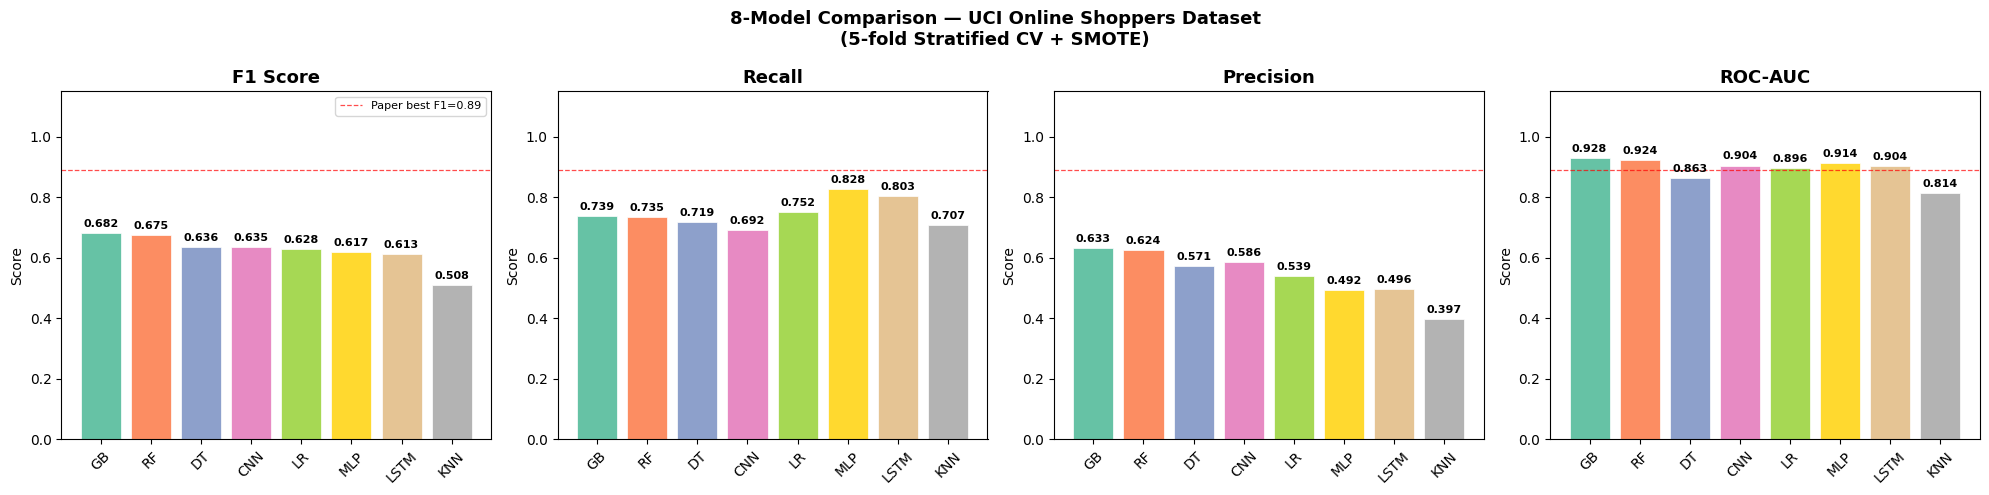

In [17]:
#Bar chart: 4 metrics for all 8 models
metric_cols = ['F1 Score', 'Recall', 'Precision', 'ROC-AUC']
model_order = result_df.index.tolist()
colors = plt.cm.Set2(np.linspace(0, 1, len(model_order)))

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, metric in enumerate(metric_cols):
    vals = result_df.loc[model_order, metric].values
    bars = axes[i].bar(model_order, vals, color=colors, edgecolor='white', linewidth=0.5)
    axes[i].set_title(metric, fontsize=13, fontweight='bold')
    axes[i].set_ylim(0, 1.15)
    axes[i].set_ylabel('Score')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].axhline(0.89, color='red', linestyle='--', linewidth=0.9,
                    alpha=0.7, label='Paper best F1=0.89')
    for bar, v in zip(bars, vals):
        axes[i].text(bar.get_x() + bar.get_width() / 2, v + 0.02,
                     f'{v:.3f}', ha='center', fontsize=8, fontweight='bold')
    if i == 0:
        axes[i].legend(fontsize=8)

plt.suptitle('8-Model Comparison — UCI Online Shoppers Dataset\n'
             f'({n_splits}-fold Stratified CV + SMOTE)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

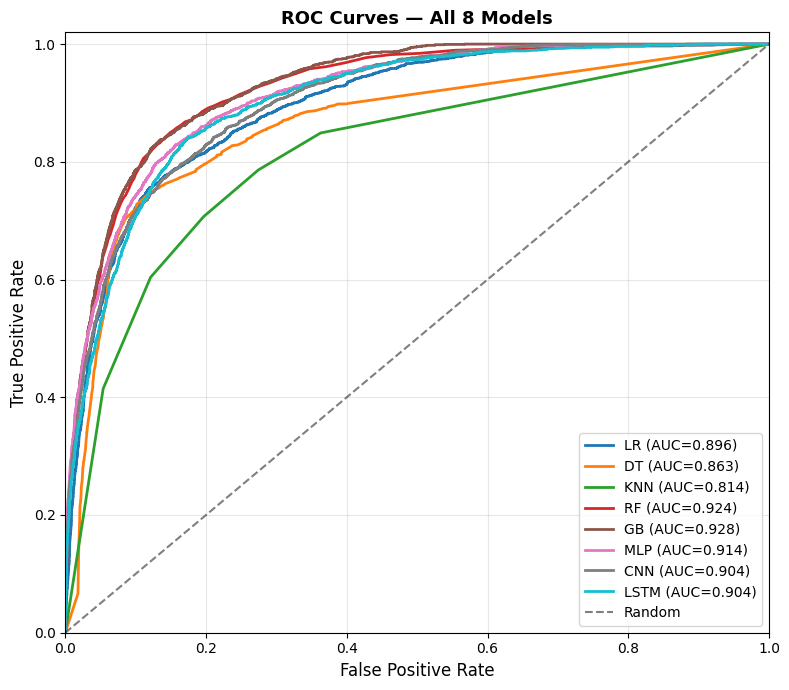

In [18]:
#ROC curves for all 8 models
fig, ax = plt.subplots(figsize=(8, 7))
roc_colors = plt.cm.tab10(np.linspace(0, 0.9, len(results)))

for (name, res), color in zip(results.items(), roc_colors):
    fpr, tpr, _ = roc_curve(res['y_true'], res['y_proba'])
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{name} (AUC={res['roc_auc']:.3f})")

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All 8 Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

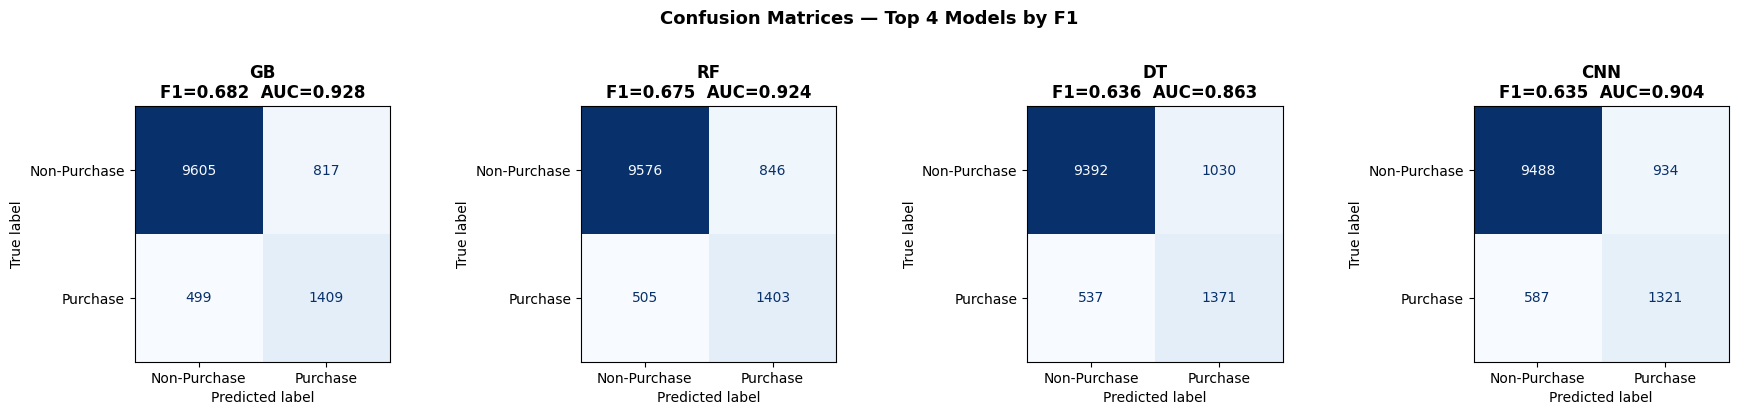

In [19]:
#Confusion matrices for top 4 models by F1
top4 = result_df.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, name in zip(axes, top4):
    res = results[name]
    cm = confusion_matrix(res['y_true'], res['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Non-Purchase', 'Purchase'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nF1={res["f1"]:.3f}  AUC={res["roc_auc"]:.3f}',
                 fontweight='bold')

plt.suptitle('Confusion Matrices — Top 4 Models by F1',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

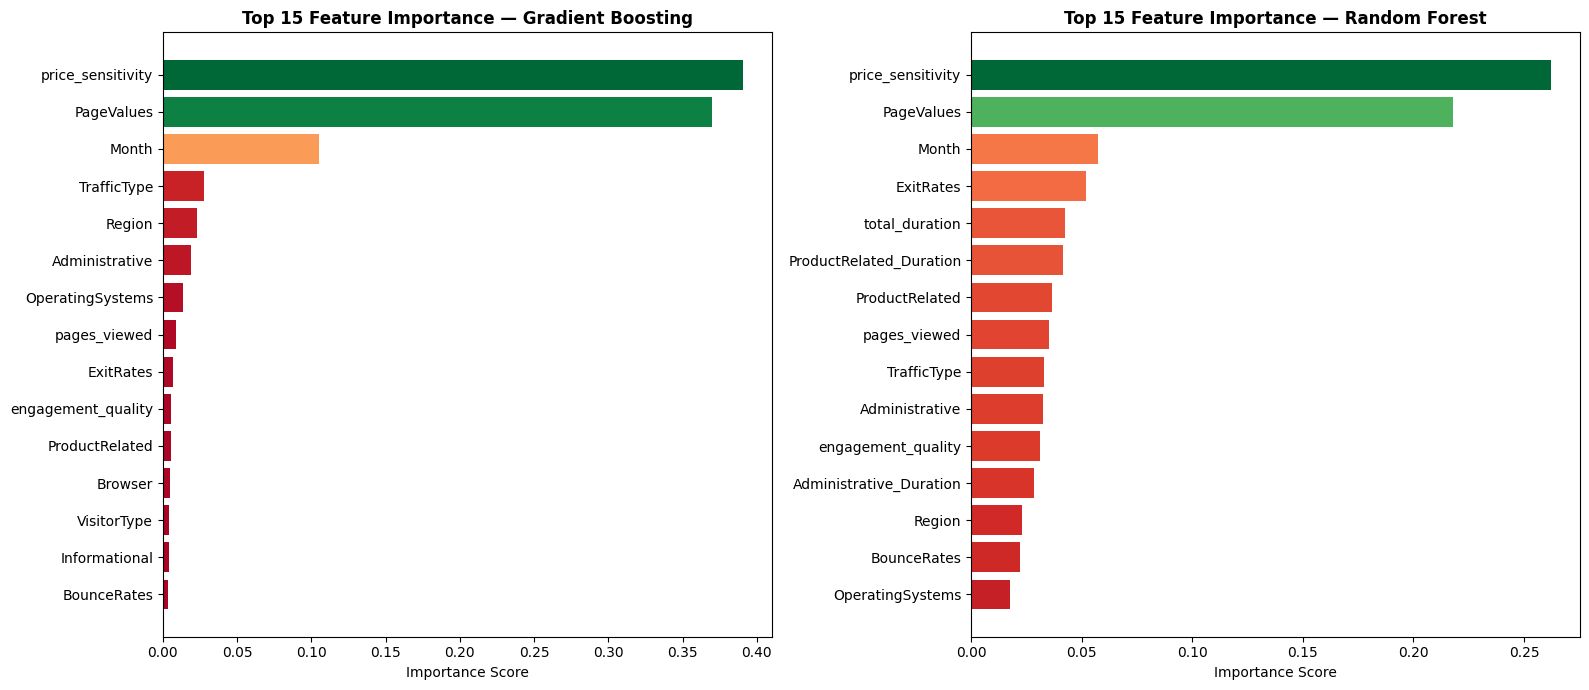

In [20]:
#Feature importance: retrain GB and RF on full SMOTE-balanced data
smote_full = SMOTE(random_state=seed)
X_sm, y_sm = smote_full.fit_resample(X, y)

gb_final = GradientBoostingClassifier(n_estimators=100, random_state=seed)
gb_final.fit(X_sm, y_sm)
rf_final = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1)
rf_final.fit(X_sm, y_sm)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
top_n = 15
for ax, (label, model_trained) in zip(axes, [('Gradient Boosting', gb_final),
                                              ('Random Forest', rf_final)]):
    importances = model_trained.feature_importances_
    idx = np.argsort(importances)[::-1][:top_n]
    feat_names = [feature_cols[i] for i in idx[::-1]]
    feat_vals  = importances[idx[::-1]]
    colors_bar = plt.cm.RdYlGn(feat_vals / feat_vals.max())
    ax.barh(feat_names, feat_vals, color=colors_bar)
    ax.set_title(f'Top {top_n} Feature Importance — {label}',
                 fontweight='bold')
    ax.set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

In [21]:
#Final summary
best_model = result_df.index[0]
best = result_df.iloc[0]
print('=' * 55)
print(f'Best model: {best_model}')
print(f'  F1 Score : {best["F1 Score"]:.4f}')
print(f'  Recall   : {best["Recall"]:.4f}')
print(f'  Precision: {best["Precision"]:.4f}')
print(f'  ROC-AUC  : {best["ROC-AUC"]:.4f}')
print('=' * 55)
print()
print('Full ranking:')
print(result_df.to_string())

Best model: GB
  F1 Score : 0.6817
  Recall   : 0.7385
  Precision: 0.6330
  ROC-AUC  : 0.9280

Full ranking:
       F1 Score  Recall  Precision  ROC-AUC
Model                                      
GB       0.6817  0.7385     0.6330   0.9280
RF       0.6750  0.7353     0.6238   0.9236
DT       0.6363  0.7186     0.5710   0.8626
CNN      0.6346  0.6923     0.5858   0.9043
LR       0.6283  0.7521     0.5395   0.8960
MLP      0.6173  0.8281     0.4921   0.9139
LSTM     0.6131  0.8035     0.4956   0.9039
KNN      0.5084  0.7070     0.3969   0.8143
